# 🔍 Semantic Question Clustering with Sentence Transformers
This notebook helps you cluster similar questions using BERT embeddings.
- Upload a CSV file with a `message` column
- Automatically cluster semantically similar questions
- Export unique and grouped questions
- Visualize cluster sizes


In [1]:
!pip install -q matplotlib scikit-learn

In [ ]:
import pandas as pd
from google.colab import files
# uploaded = files.upload()
# file_name = list(uploaded.keys())[0]
df = pd.read_csv("Support (1).csv")
df.dropna(subset=['message'], inplace=True)
df['message'] = df['message'].astype(str).str.strip()
df = df[df['message'] != '']
df.head()

,objectId,mobile,appNo,message,ACL,name,updatedAt,status,cat,createdAt,email,roll no
0,00F4ZoPTmY,9.1982E+11,90820148,login user id and password,NaN,Tabish Alam,Tue Aug 06 2024 10:31:12 GMT+0530 (India Stand...,closed,NaN,Tue Aug 06 2024 10:31:12 GMT+0530 (India Stand...,itabishalam@gmail.com,6900182
1,014XfcLP0h,9648661350,24511002585p,Registration not login,NaN,RITIK PANDEY,Sun Aug 25 2024 18:17:30 GMT+0530 (India Stand...,closed,NaN,Sun Aug 25 2024 18:17:30 GMT+0530 (India Stand...,mohanpandey5858@gmail.com,UP23013589
2,01kjBD7S63,8630976325,90658815,I am not be able to apply for counselling,NaN,Kanishka jadaun,Mon Jul 15 2024 16:53:49 GMT+0530 (India Stand...,closed,NaN,Mon Jul 15 2024 16:53:49 GMT+0530 (India Stand...,kanishkajadon67@gmail.com,6019010
3,01pXeHPg98,9520459475,90677591,Unable to login and forgot password,NaN,Sakshi Sharma,Sat Jul 06 2024 17:43:15 GMT+0530 (India Stand...,closed,NaN,Sat Jul 06 2024 17:43:15 GMT+0530 (India Stand...,devrajkumarsharma01@gmail.com,6074989
4,04D7AXnSHn,8809528637,90777091,Login problem,NaN,Ghazi Kauser,Mon Jul 08 2024 23:20:34 GMT+0530 (India Stand...,closed,NaN,Mon Jul 08 2024 23:20:34 GMT+0530 (India Stand...,ghazikau@gmail.com,6062520


In [4]:
from sentence_transformers import SentenceTransformer, util
from sklearn.cluster import DBSCAN
import numpy as np

model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df['message'].tolist(), convert_to_tensor=True, show_progress_bar=True)

cosine_scores = util.pytorch_cos_sim(embeddings, embeddings).cpu().numpy()
distances = 1 - cosine_scores
distances = np.clip(distances, 0, 1)  # ✅ fix here

clustering = DBSCAN(eps=0.35, min_samples=2, metric='precomputed')
labels = clustering.fit_predict(distances)
df['cluster_id'] = labels
df_clustered = df[df['cluster_id'] != -1]

Batches: 100%|██████████| 80/80 [00:01<00:00, 42.32it/s]


In [ ]:
# Save CSVs locally
unique_questions = df_clustered.groupby('cluster_id')['message'].first().reset_index()
grouped_questions = df_clustered.groupby('cluster_id')['message'].apply(list).reset_index()
unique_questions.to_csv("Semantic_Unique_Questions_1.csv", index=False)
grouped_questions.to_csv("Semantic_Cluster_Details_1.csv", index=False)

# REMOVE or COMMENT OUT these lines ↓
# from google.colab import files
# files.download("Semantic_Unique_Questions.csv")
# files.download("Semantic_Cluster_Details.csv")

In [7]:
# unique_questions = df_clustered.groupby('cluster_id')['message'].first().reset_index()
# grouped_questions = df_clustered.groupby('cluster_id')['message'].apply(list).reset_index()

# unique_questions.to_csv("Semantic_Unique_Questions.csv", index=False)
# grouped_questions.to_csv("Semantic_Cluster_Details.csv", index=False)

# from google.colab import files
# files.download("Semantic_Unique_Questions.csv")
# files.download("Semantic_Cluster_Details.csv")

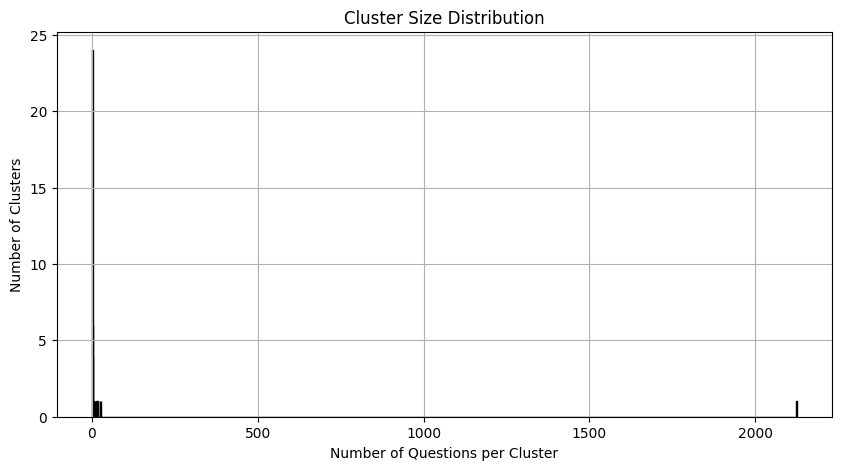

In [8]:
import matplotlib.pyplot as plt
sizes = df_clustered.groupby('cluster_id').size()
plt.figure(figsize=(10, 5))
plt.hist(sizes, bins=range(1, sizes.max()+2), edgecolor='black')
plt.title("Cluster Size Distribution")
plt.xlabel("Number of Questions per Cluster")
plt.ylabel("Number of Clusters")
plt.grid(True)
plt.show()